In [35]:
%reload_ext autoreload
%autoreload 2

%matplotlib inline

import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we run from project root so `data/raw` resolves correctly
if Path.cwd().name == "notebooks":
    os.chdir("..")


project_root = str(Path.cwd())
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print(f"CWD: {Path.cwd()}")

CWD: c:\Users\reymo\.cursor\Almgren_Chriss_problem


In [36]:
# Dynamically add the 'src' directory to Python's path
sys.path.append(os.path.abspath('./src'))


from derivation import DiscreteAlmgrenChriss
from simulation import Monte_Carlo_Simulator

In [37]:
X_total: float = 10000.0        # Initial inventory
T_horizon: float = 1.0          # Time horizon (e.g., 1 day)
N_steps: int = 50               # Number of trading intervals
M: int = 10000
S0: float = 100.0
sigma_vol: float = 0.3          # Arithmetic volatility
eta_temp: float = 2 * 10e-5          # Temporary market impact
gamma_perm: float = 1 * 10e-5       # Permanent market impact
tau: float = T_horizon / N_steps

lambdas = np.logspace(-6, -1, num=50, base=10)

Empirical_E = np.zeros(len(lambdas))
Empirical_V = np.zeros(len(lambdas))

theoretical_E = np.zeros(len(lambdas))
theoretical_V = np.zeros(len(lambdas))

for i in range(len(lambdas)):
    ac_model = DiscreteAlmgrenChriss(
        X=X_total,
        T=T_horizon,
        N=N_steps,
        sigma=sigma_vol,
        eta=eta_temp,
        gamma=gamma_perm,
        lambda_penalty=lambdas[i],
    )
    x = ac_model.solve_trajectory()
    v = x[:-1] - x[1:]

    theoretical_E[i] = (-gamma_perm * X_total * np.sum(v) + gamma_perm * np.dot(v, x[:-1]) - (eta_temp / tau) * np.sum(v**2))
    theoretical_V[i] = (sigma_vol**2) * tau * np.sum(x[1:-1]**2)

    MCS = Monte_Carlo_Simulator(
        X=X_total,
        T=T_horizon,
        N=N_steps,
        M=M,
        x=x,
        v=v,
        S0=S0,
        sigma=sigma_vol,
        eta=eta_temp,
        gamma=gamma_perm,
    )


    expectation, variance = MCS.empirical_simulation()
    Empirical_E[i] = expectation
    Empirical_V[i] = variance

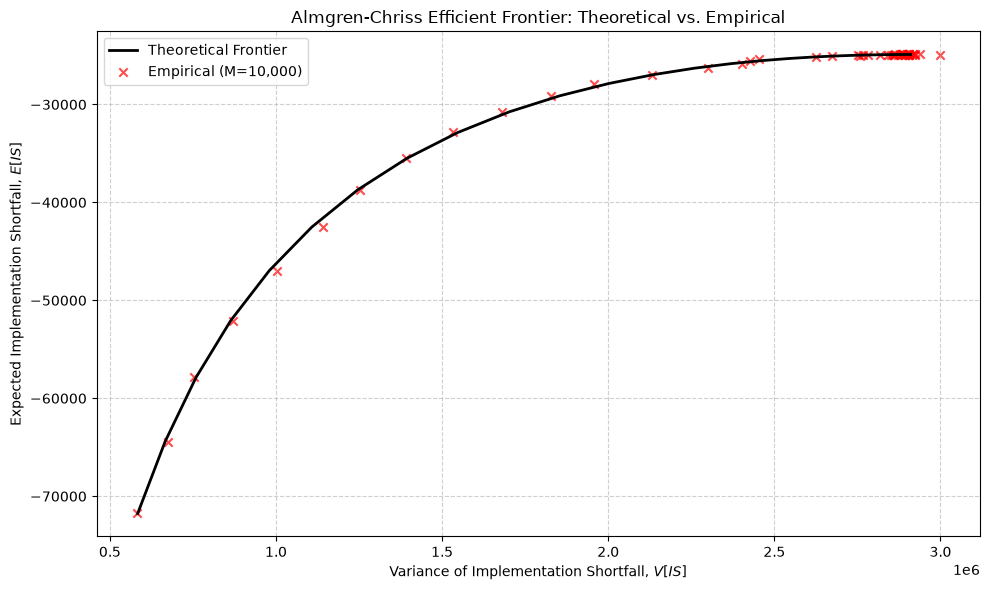

In [38]:
plt.figure(figsize=(10, 6))

# Plot Theoretical Efficient Frontier (Continuous Line)
plt.plot(theoretical_V, theoretical_E, color='black', linewidth=2, label='Theoretical Frontier')

# Plot Empirical Monte Carlo Results (Discrete Points)
plt.scatter(Empirical_V, Empirical_E, color='red', marker='x', alpha=0.7, label='Empirical (M=10,000)')

plt.title('Almgren-Chriss Efficient Frontier: Theoretical vs. Empirical')
plt.xlabel('Variance of Implementation Shortfall, $V[IS]$')
plt.ylabel('Expected Implementation Shortfall, $E[IS]$')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Initializing Phase 3 Pipeline...
Configuring Historical Bootstrapper...
Running Empirical Monte Carlo over 1500 historical paths...

--- Monte Carlo Historical Bootstrapping Results ---
Static Phase 1  | E[IS]: $1,296.65 | Var[IS]: 1.43e+09
Dynamic Phase 3 | E[IS]: $2,231.87 | Var[IS]: 1.36e+09


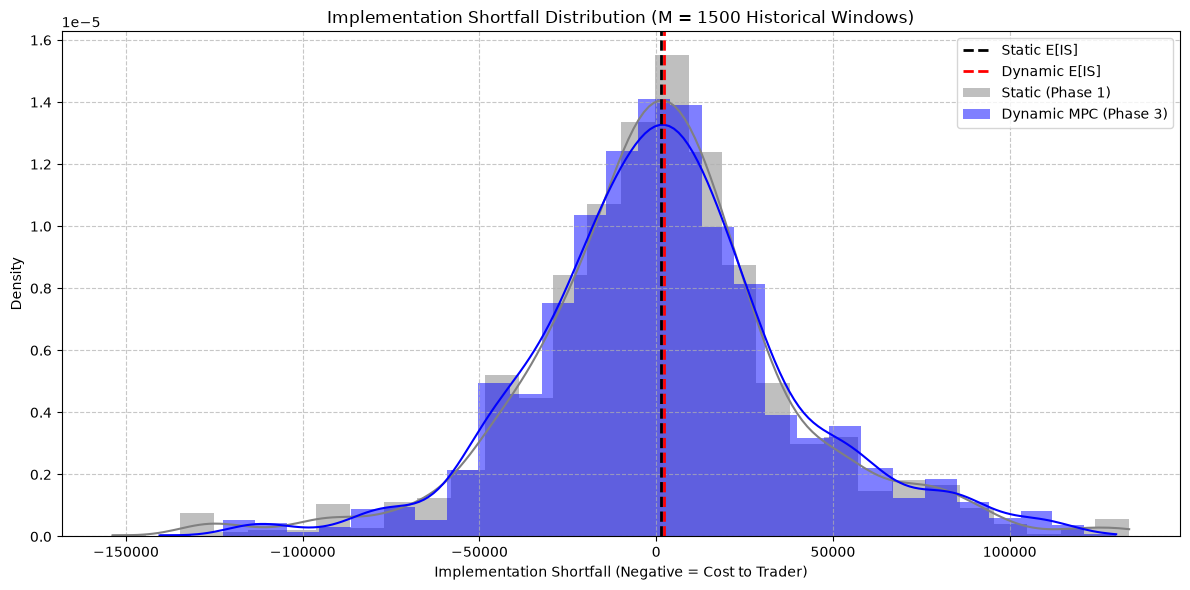

In [41]:
from src.simulation import Historical_Bootstrapper
from src.main import dynamic_execution

# 1. Run Phase 3 to train the models and extract the pipeline state
print("Initializing Phase 3 Pipeline...")
pipeline_state = dynamic_execution(plot = False)

# Unpack the required variables
df = pipeline_state["df"]
X_features = pipeline_state["feature_matrix"]
X_total = pipeline_state["X_total"]
N_steps = pipeline_state["N_steps"]
T_horizon = pipeline_state["T_horizon"]
static_trajectory = pipeline_state["static_trajectory"]
dynamic_engine = pipeline_state["dynamic_engine"]
sigma_model = pipeline_state["sigma_model"]
eta_model = pipeline_state["eta_model"]
y_eta = pipeline_state["y_eta"]

# 2. Setup the Bootstrapper
print("Configuring Historical Bootstrapper...")
bootstrapper = Historical_Bootstrapper(
    df=df, 
    feature_matrix=X_features, 
    X=X_total, 
    N=N_steps, 
    tau=T_horizon / N_steps
)

static_v = static_trajectory[:-1] - static_trajectory[1:]
eval_eta = np.mean(np.exp(y_eta)) 

# 3. Run Simulation 
M_simulations = 1500
print(f"Running Empirical Monte Carlo over {M_simulations} historical paths...")
results = bootstrapper.run_bootstrap(
    M=M_simulations, 
    dynamic_engine=dynamic_engine, 
    sigma_model=sigma_model, 
    eta_model=eta_model, 
    static_v=static_v, 
    eval_eta=eval_eta
)

# 4. Extract and Print Results
static_IS = results["Static_IS"]
dynamic_IS = results["Dynamic_IS"]
metrics = results["Metrics"]

print("\n--- Monte Carlo Historical Bootstrapping Results ---")
print(f"Static Phase 1  | E[IS]: ${metrics['Static']['Expectation']:,.2f} | Var[IS]: {metrics['Static']['Variance']:,.2e}")
print(f"Dynamic Phase 3 | E[IS]: ${metrics['Dynamic']['Expectation']:,.2f} | Var[IS]: {metrics['Dynamic']['Variance']:,.2e}")

# 5. Plot the Distributions
plt.figure(figsize=(12, 6))

sns.histplot(static_IS, color='gray', label='Static (Phase 1)', kde=True, stat="density", linewidth=0, alpha=0.5, bins=30)
sns.histplot(dynamic_IS, color='blue', label='Dynamic MPC (Phase 3)', kde=True, stat="density", linewidth=0, alpha=0.5, bins=30)

plt.axvline(metrics['Static']['Expectation'], color='black', linestyle='dashed', linewidth=2, label='Static E[IS]')
plt.axvline(metrics['Dynamic']['Expectation'], color='red', linestyle='dashed', linewidth=2, label='Dynamic E[IS]')

plt.title(f"Implementation Shortfall Distribution (M = {M_simulations} Historical Windows)")
plt.xlabel("Implementation Shortfall (Negative = Cost to Trader)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()